# Indoor Fire Smoke Dataset — ViT-B/16 Multi-Label Classification
**Complete Google Colab workflow: inspect data → augment → fine-tune → evaluate → save → reload for prediction**

**Dataset:** Indoor Fire Smoke Dataset (Roboflow Universe, Version 1)  
**Annotation mapping supplied for this project:** class `0 = Fire`, class `1 = Smoke`  
**Task:** Image-level multi-label classification. An image can contain Fire, Smoke, or both.

## Workflow and important safeguards
1. Mount Google Drive and locate the ZIP.
2. Extract the dataset and locate `train`, `valid`, `test`, and `data.yaml`.
3. Inspect split counts, labels, annotation validity, image examples, and exact duplicates.
4. Convert YOLO object annotations to two image-level targets: `[Fire, Smoke]`.
5. **Stop for manual review** if labels are missing, malformed, or empty. An empty label file is not automatically treated as a negative/normal image.
6. Apply augmentation dynamically to training images only.
7. Fine-tune a pretrained Hugging Face ViT-B/16 with a two-output sigmoid-based multi-label objective (BCE with logits).
8. Evaluate each epoch on validation data and save the best checkpoint.
9. Evaluate once on the untouched test split.
10. Save the model and image processor to Google Drive; reload them later without retraining.

This notebook does not generate synthetic images. It preserves the dataset's original train/valid/test splits. It does not claim every source image is authentic; provenance depends on the dataset provider. Run cells in order. If an inspection cell stops with an error, share that output before bypassing the check.

## 1. Set up the Colab runtime

In Google Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU). The notebook can run on CPU, but training will be much slower.

In [ ]:
!pip -q install "transformers>=4.45,<5" scikit-learn pyyaml seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 46.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports and reproducibility

In [ ]:
import os, json, zipfile, shutil, hashlib, random, copy, time
from pathlib import Path
from collections import defaultdict

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    precision_recall_fscore_support, accuracy_score,
    classification_report, multilabel_confusion_matrix, f1_score
)
from transformers import ViTImageProcessor, ViTForImageClassification, set_seed

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
SPLITS = ['train', 'valid', 'test']
CLASS_NAMES = ['Fire', 'Smoke']
CLASS_ID_TO_NAME = {0: 'Fire', 1: 'Smoke'}

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 3. Mount Google Drive and set project paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_PROJECT = Path('/content/drive/MyDrive/ViT_Fire_Smoke_Project')
DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)

# Expected ZIP location. Change this if you used a different Drive folder/name.
ZIP_PATH = DRIVE_PROJECT / 'Indoor_Fire_Smoke.zip'
if not ZIP_PATH.exists():
    # Search Drive for a matching ZIP if it is in a different folder.
    matches = list(Path('/content/drive/MyDrive').rglob('Indoor_Fire_Smoke.zip'))
    if matches:
        ZIP_PATH = matches[0]
    else:
        raise FileNotFoundError(
            "Could not find Indoor_Fire_Smoke.zip in MyDrive. "
            "Upload it to MyDrive or update ZIP_PATH to the exact location."
        )

print("Dataset ZIP:", ZIP_PATH)
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))

Mounted at /content/drive
Dataset ZIP: /content/drive/MyDrive/Indoor_Fire_Smoke.zip
ZIP size (MB): 187.01


## 4. Extract the dataset

In [ ]:
EXTRACT_DIR = Path('/content/Indoor_Fire_Smoke_Extracted')
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    bad_member = z.testzip()
    if bad_member is not None:
        raise ValueError(f"ZIP integrity check failed at: {bad_member}")
    z.extractall(EXTRACT_DIR)

print("Extracted to:", EXTRACT_DIR)
print("Top-level entries:")
for p in list(EXTRACT_DIR.iterdir())[:30]:
    print(("DIR " if p.is_dir() else "FILE"), p.name)

Extracted to: /content/Indoor_Fire_Smoke_Extracted
Top-level entries:
DIR  Indoor Fire Smoke


## 5. Locate dataset root and read `data.yaml`

In [ ]:
def find_dataset_root(base_dir):
    required = ['train/images', 'train/labels',
                'valid/images', 'valid/labels',
                'test/images', 'test/labels']
    for folder in [base_dir] + [p for p in base_dir.rglob('*') if p.is_dir()]:
        if all((folder / rel).is_dir() for rel in required) and (folder / 'data.yaml').is_file():
            return folder
    return None

DATASET_ROOT = find_dataset_root(EXTRACT_DIR)
if DATASET_ROOT is None:
    print("First 100 ZIP entries:")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        for name in z.namelist()[:100]:
            print(name)
    raise FileNotFoundError(
        "Expected train/valid/test images and labels plus data.yaml not found. "
        "Inspect the printed paths and tell me what differs."
    )

with open(DATASET_ROOT / 'data.yaml', 'r', encoding='utf-8') as f:
    data_config = yaml.safe_load(f)

print("Dataset root:", DATASET_ROOT)
print("\ndata.yaml:")
print(yaml.safe_dump(data_config, sort_keys=False))
print("\nProject class mapping used:", CLASS_ID_TO_NAME)

Dataset root: /content/Indoor_Fire_Smoke_Extracted/Indoor Fire Smoke

data.yaml:
path: your_path
train: train/images
val: valid/images
test: test/images
nc: 2
names:
- '0'
- '1'
roboflow:
  workspace: object-detection-7qn6l
  project: indoor-fire-smoke
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/object-detection-7qn6l/indoor-fire-smoke/dataset/1


Project class mapping used: {0: 'Fire', 1: 'Smoke'}


## 6. Count images and label files in each original split

In [ ]:
split_summary, split_image_paths = [], {}
for split in SPLITS:
    image_dir = DATASET_ROOT / split / 'images'
    label_dir = DATASET_ROOT / split / 'labels'
    images = sorted(p for p in image_dir.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
    labels = sorted(p for p in label_dir.rglob('*') if p.is_file() and p.suffix.lower() == '.txt')
    split_image_paths[split] = images
    image_stems, label_stems = {p.stem for p in images}, {p.stem for p in labels}
    split_summary.append({
        'split': split, 'images': len(images), 'label_files': len(labels),
        'images_without_matching_label': len(image_stems - label_stems),
        'labels_without_matching_image': len(label_stems - image_stems)
    })
split_summary_df = pd.DataFrame(split_summary)
display(split_summary_df)

,split,images,label_files,images_without_matching_label,labels_without_matching_image
0,train,3500,3500,0,0
1,valid,750,750,0,0
2,test,750,750,0,0


## 7. Validate YOLO annotations and derive image-level labels

In [ ]:
annotation_rows, target_rows, annotation_issues = [], [], []

for split in SPLITS:
    for image_path in split_image_paths[split]:
        label_path = DATASET_ROOT / split / 'labels' / f'{image_path.stem}.txt'
        if not label_path.exists():
            annotation_issues.append({'split': split, 'image': image_path.name, 'issue': 'Missing label file'})
            continue
        try:
            with open(label_path, 'r', encoding='utf-8') as f:
                lines = [line.strip() for line in f if line.strip()]
            if len(lines) == 0:
                annotation_issues.append({
                    'split': split, 'image': image_path.name,
                    'issue': 'Empty label file: meaning must be verified before training'
                })
                continue

            present = set()
            for line_num, line in enumerate(lines, start=1):
                values = line.split()
                if len(values) != 5:
                    raise ValueError(f"Line {line_num}: expected 5 values, got {len(values)}")
                class_value = float(values[0])
                if not class_value.is_integer():
                    raise ValueError(f"Line {line_num}: class ID must be an integer")
                class_id = int(class_value)
                if class_id not in CLASS_ID_TO_NAME:
                    raise ValueError(f"Line {line_num}: unexpected class ID {class_id}")
                coords = np.asarray([float(v) for v in values[1:]], dtype=float)
                if not np.isfinite(coords).all():
                    raise ValueError(f"Line {line_num}: non-finite coordinate")
                xc, yc, bw, bh = coords
                if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
                    raise ValueError(f"Line {line_num}: invalid normalized bounding box {coords.tolist()}")
                present.add(class_id)
                annotation_rows.append({
                    'split': split, 'image': image_path.name,
                    'class_id': class_id, 'class_name': CLASS_ID_TO_NAME[class_id],
                    'x_center': xc, 'y_center': yc, 'width': bw, 'height': bh
                })

            target_rows.append({
                'split': split, 'image_path': str(image_path), 'label_path': str(label_path),
                'Fire': int(0 in present), 'Smoke': int(1 in present)
            })
        except Exception as e:
            annotation_issues.append({'split': split, 'image': image_path.name, 'issue': str(e)})

annotations_df = pd.DataFrame(annotation_rows)
targets_df = pd.DataFrame(target_rows)
issues_df = pd.DataFrame(annotation_issues)

print("Images converted to targets:", len(targets_df))
print("Valid annotation rows:", len(annotations_df))
print("Issues requiring review:", len(issues_df))
display(issues_df.head(40))

Images converted to targets: 5000
Valid annotation rows: 6935
Issues requiring review: 0


""


## 8. Safety gate: confirm annotations before training
Training must not proceed with unknown/missing/empty labels because they could be incorrectly treated as negative examples. If this cell raises an error, inspect the report and confirm the dataset's annotation convention before changing the gate.

In [ ]:
if targets_df.empty:
    raise ValueError("No valid image targets were created. Inspect annotation issues.")
if not issues_df.empty:
    issues_path = DRIVE_PROJECT / 'annotation_issues.csv'
    issues_df.to_csv(issues_path, index=False)
    raise ValueError(
        f"{len(issues_df)} missing, empty, or invalid annotation issue(s) found. "
        f"Review {issues_path}. Do not train until these are understood."
    )

print("Annotation gate passed: every image has a non-empty, valid label file.")

Annotation gate passed: every image has a non-empty, valid label file.


## 9. Summarize class combinations and distributions

combination,Fire + Smoke,Fire only,Smoke only
split,,,
test,66,326,358
train,315,1520,1665
valid,78,319,353


,Fire,Smoke
split,,
test,392,424
train,1835,1980
valid,397,431


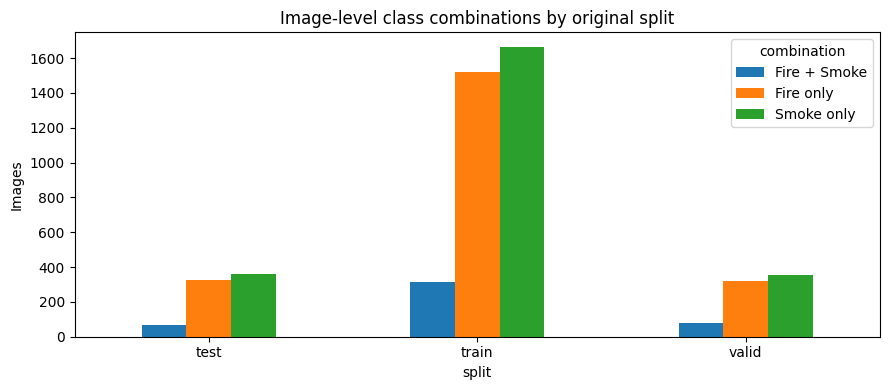

In [ ]:
targets_df['combination'] = targets_df.apply(
    lambda r: 'Fire + Smoke' if r['Fire'] and r['Smoke']
    else 'Fire only' if r['Fire']
    else 'Smoke only', axis=1
)
display(pd.crosstab(targets_df['split'], targets_df['combination']))
display(targets_df.groupby('split')[['Fire', 'Smoke']].sum())

counts = targets_df.groupby(['split', 'combination']).size().unstack(fill_value=0)
counts.plot(kind='bar', figsize=(9, 4))
plt.title('Image-level class combinations by original split')
plt.ylabel('Images')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Visualize annotated examples

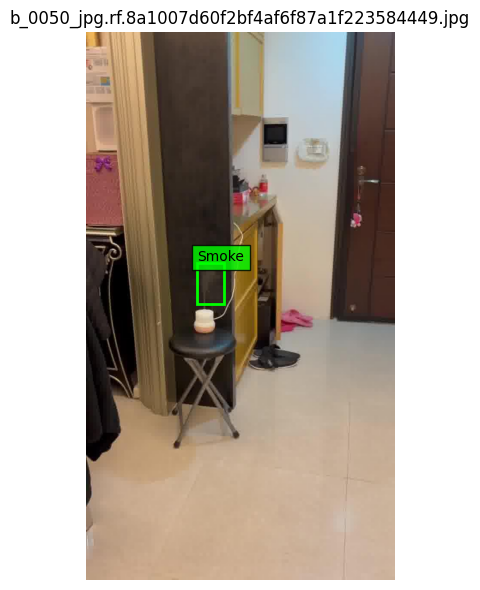

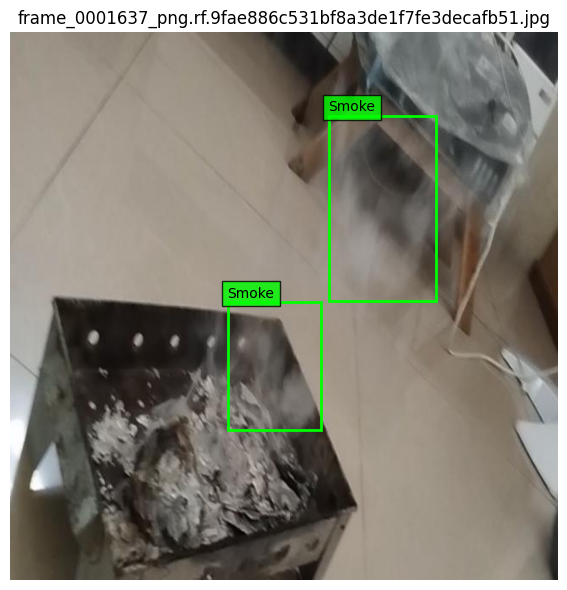

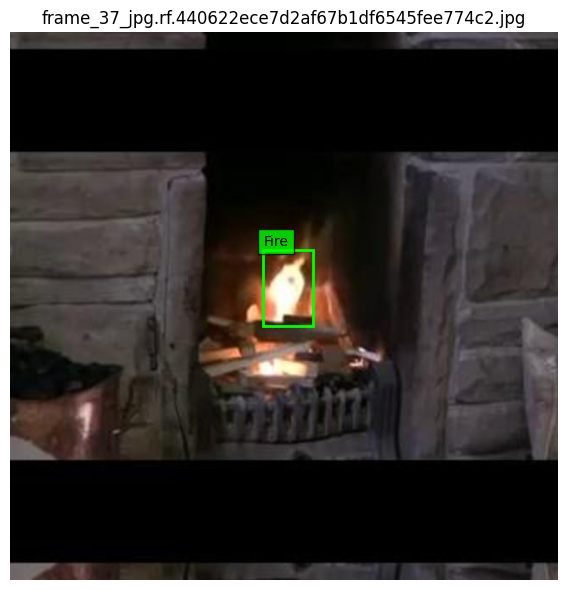

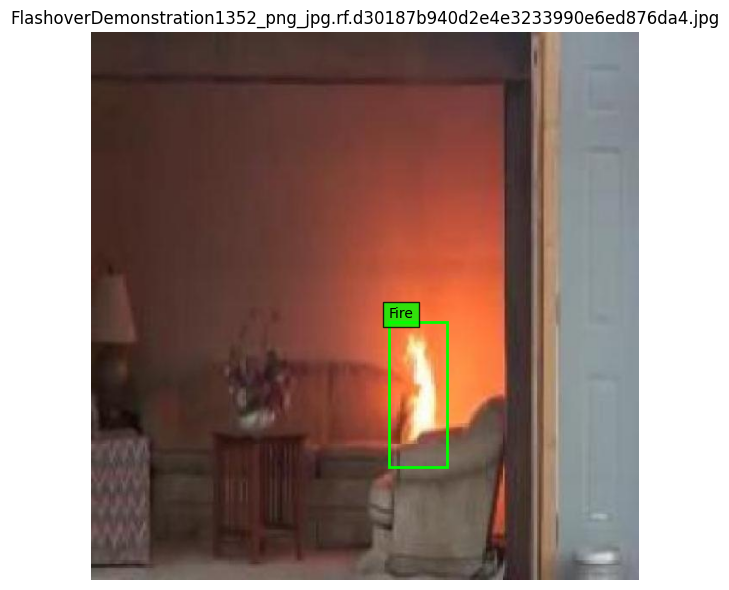

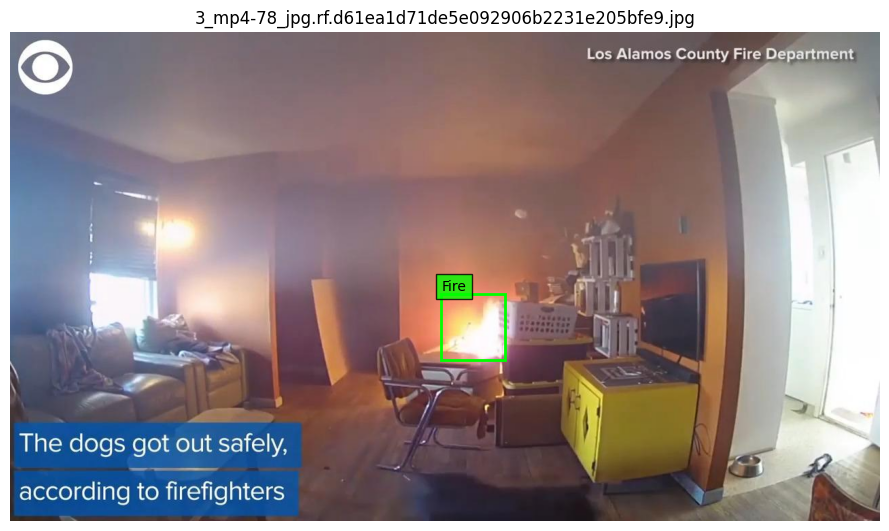

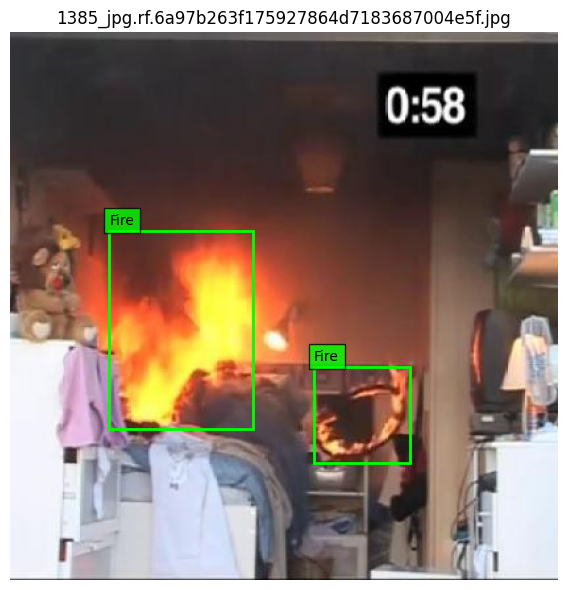

In [ ]:
def show_annotated_image(image_path, label_path):
    image = Image.open(image_path).convert('RGB')
    width, height = image.size
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(image)
    with open(label_path, 'r', encoding='utf-8') as f:
        lines = [line.strip() for line in f if line.strip()]
    for line in lines:
        class_id, xc, yc, bw, bh = map(float, line.split())
        class_id = int(class_id)
        x1, y1 = (xc - bw/2) * width, (yc - bh/2) * height
        ax.add_patch(patches.Rectangle(
            (x1, y1), bw * width, bh * height,
            linewidth=2, edgecolor='lime', facecolor='none'
        ))
        ax.text(x1, max(0, y1 - 5), CLASS_ID_TO_NAME[class_id],
                color='black', fontsize=10, bbox=dict(facecolor='lime', alpha=0.8))
    ax.set_title(Path(image_path).name)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

sample = annotations_df[['split', 'image']].drop_duplicates()
sample = sample.sample(min(6, len(sample)), random_state=SEED)
for _, row in sample.iterrows():
    img = DATASET_ROOT / row['split'] / 'images' / row['image']
    lbl = DATASET_ROOT / row['split'] / 'labels' / f"{Path(row['image']).stem}.txt"
    if img.exists() and lbl.exists():
        show_annotated_image(img, lbl)

## 11. Check exact duplicate image content across splits

In [ ]:
hash_to_files = defaultdict(list)
for split in SPLITS:
    for image_path in split_image_paths[split]:
        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_to_files[digest].append((split, str(image_path)))

cross_split_duplicates = []
for digest, items in hash_to_files.items():
    if len({split for split, _ in items}) > 1:
        cross_split_duplicates.append({'sha256': digest, 'files': items})

print("Exact duplicate groups spanning splits:", len(cross_split_duplicates))
for item in cross_split_duplicates[:20]:
    print(item)

Exact duplicate groups spanning splits: 0


## 12. Create train/validation/test datasets and augmentation

In [ ]:
MODEL_CHECKPOINT = 'google/vit-base-patch16-224-in21k'
image_processor = ViTImageProcessor.from_pretrained(MODEL_CHECKPOINT)

if isinstance(image_processor.size, dict):
    IMAGE_SIZE = image_processor.size.get('height', 224)
else:
    IMAGE_SIZE = int(image_processor.size)

mean, std = image_processor.image_mean, image_processor.image_std

# Training-only augmentation: modest flip, rotation, and brightness/contrast changes.
# These preserve image-level presence labels; validation/test remain deterministic.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.06, hue=0.015),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

class FireSmokeDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row['image_path']) as im:
            image = im.convert('RGB')
        pixel_values = self.transform(image)
        labels = torch.tensor([row['Fire'], row['Smoke']], dtype=torch.float32)
        return pixel_values, labels

train_df = targets_df[targets_df['split'] == 'train'].copy()
valid_df = targets_df[targets_df['split'] == 'valid'].copy()
test_df = targets_df[targets_df['split'] == 'test'].copy()

if min(len(train_df), len(valid_df), len(test_df)) == 0:
    raise ValueError("One of the original train/valid/test splits has no valid targets.")

train_dataset = FireSmokeDataset(train_df, train_transform)
valid_dataset = FireSmokeDataset(valid_df, eval_transform)
test_dataset = FireSmokeDataset(test_df, eval_transform)

BATCH_SIZE = 16
NUM_WORKERS = 2
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print("Image size:", IMAGE_SIZE)
print("Split sizes:", len(train_dataset), len(valid_dataset), len(test_dataset))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Image size: 224
Split sizes: 3500 750 750


## 13. Preview original versus augmented images

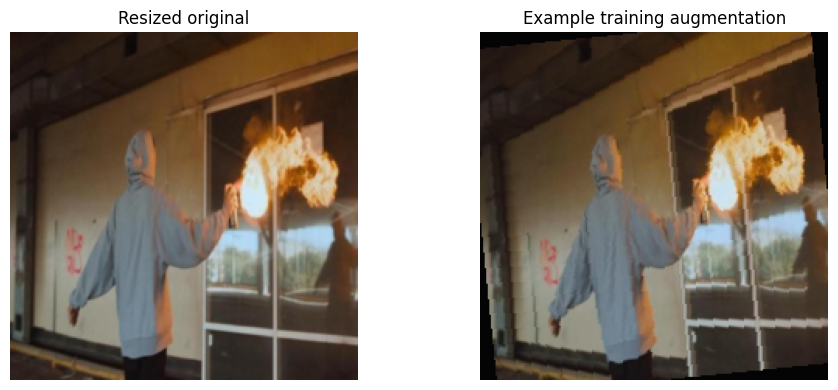

Image-level target: [1, 0]


In [ ]:
# Show one training image after deterministic resize and one randomly augmented view.
sample_row = train_df.iloc[0]
with Image.open(sample_row['image_path']) as im:
    original = im.convert('RGB')

preview_base = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))])
augmented = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.06, hue=0.015)
])(original)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(preview_base(original)); axes[0].set_title("Resized original")
axes[1].imshow(augmented); axes[1].set_title("Example training augmentation")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()
print("Image-level target:", [int(sample_row['Fire']), int(sample_row['Smoke'])])

## 14. Initialize ViT-B/16 for multi-label classification

In [ ]:
id2label = {0: 'Fire', 1: 'Smoke'}
label2id = {'Fire': 0, 'Smoke': 1}

model = ViTForImageClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
    problem_type='multi_label_classification',
    ignore_mismatched_sizes=True
).to(DEVICE)

# Positive weights can help if a class is less common; cap to avoid extreme weighting.
train_targets = train_df[['Fire', 'Smoke']].to_numpy(dtype=np.float32)
positive = train_targets.sum(axis=0)
negative = len(train_targets) - positive
pos_weight = torch.tensor(
    np.clip(negative / np.maximum(positive, 1), 1.0, 10.0),
    dtype=torch.float32, device=DEVICE
)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print("Model:", MODEL_CHECKPOINT)
print("Positive counts [Fire, Smoke]:", positive.tolist())
print("pos_weight:", pos_weight.detach().cpu().numpy().tolist())
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: google/vit-base-patch16-224-in21k
Positive counts [Fire, Smoke]: [1835.0, 1980.0]
pos_weight: [1.0, 1.0]
Trainable parameters: 85800194


## 15. Configure training

In [ ]:
EPOCHS = 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
PATIENCE = 3
THRESHOLD = 0.5

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

BEST_MODEL_DIR = DRIVE_PROJECT / 'best_model'
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"Epochs={EPOCHS}, batch={BATCH_SIZE}, lr={LEARNING_RATE}, threshold={THRESHOLD}")

Epochs=8, batch=16, lr=2e-05, threshold=0.5


## 16. Train and validate; save best checkpoint

In [ ]:

from tqdm.auto import tqdm
import torch
import numpy as np
import pandas as pd
import time
import copy
from sklearn.metrics import f1_score

def run_epoch(loader, training, epoch_num, phase):
    model.train(training)

    losses = []
    all_probs = []
    all_labels = []

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch_num}/{EPOCHS} - {phase}",
        leave=True
    )

    for batch_idx, (pixel_values, labels) in enumerate(progress, start=1):
        pixel_values = pixel_values.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type='cuda',
                dtype=torch.float16,
                enabled=use_amp
            ):
                logits = model(pixel_values=pixel_values).logits
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        losses.append(loss.detach().item())
        all_probs.append(torch.sigmoid(logits.detach()).cpu().numpy())
        all_labels.append(labels.detach().cpu().numpy())

        # Display running loss after every batch
        progress.set_postfix(
            loss=f"{np.mean(losses):.4f}"
        )

    probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_labels).astype(int)
    y_pred = (probs >= THRESHOLD).astype(int)

    macro_f1 = f1_score(
        y_true, y_pred,
        average='macro',
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_true, y_pred,
        average=None,
        labels=[0, 1],
        zero_division=0
    )

    return {
        'loss': float(np.mean(losses)),
        'macro_f1': float(macro_f1),
        'fire_f1': float(per_class_f1[0]),
        'smoke_f1': float(per_class_f1[1]),
        'probs': probs,
        'labels': y_true
    }


history = []
best_val_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    print(f"\n{'='*50}")
    print(f"STARTING EPOCH {epoch}/{EPOCHS}")
    print(f"{'='*50}", flush=True)

    train_metrics = run_epoch(
        train_loader,
        training=True,
        epoch_num=epoch,
        phase="Training"
    )

    with torch.no_grad():
        val_metrics = run_epoch(
            valid_loader,
            training=False,
            epoch_num=epoch,
            phase="Validation"
        )

    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'val_loss': val_metrics['loss'],
        'val_macro_f1': val_metrics['macro_f1'],
        'val_fire_f1': val_metrics['fire_f1'],
        'val_smoke_f1': val_metrics['smoke_f1'],
        'seconds': round(time.time() - start, 1)
    }

    history.append(row)

    print("\nEpoch results:", row, flush=True)

    if val_metrics['macro_f1'] > best_val_f1:
        best_val_f1 = val_metrics['macro_f1']
        epochs_without_improvement = 0

        model.save_pretrained(BEST_MODEL_DIR)
        image_processor.save_pretrained(BEST_MODEL_DIR)

        with open(BEST_MODEL_DIR / 'class_labels.json', 'w') as f:
            import json
            json.dump({
                'class_names': CLASS_NAMES,
                'threshold': THRESHOLD
            }, f, indent=2)

        print("Best model checkpoint saved.", flush=True)

    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping triggered.", flush=True)
            break

    history_df = pd.DataFrame(history)
    display(history_df.tail(1))



STARTING EPOCH 1/8


Epoch 1/8 - Training:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 1/8 - Validation:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch results: {'epoch': 1, 'train_loss': 0.3118237107311754, 'val_loss': 0.1642846406457272, 'val_macro_f1': 0.9647698926286107, 'val_fire_f1': 0.9798994974874372, 'val_smoke_f1': 0.9496402877697842, 'seconds': 59.5}
Best model checkpoint saved.


,epoch,train_loss,val_loss,val_macro_f1,val_fire_f1,val_smoke_f1,seconds
0,1,0.311824,0.164285,0.96477,0.979899,0.94964,59.5


...


STARTING EPOCH 7/8


Epoch 7/8 - Training:   0%|          | 0/219 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78123c357740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78123c357740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 7/8 - Validation:   0%|          | 0/47 [00:00<?, ?it/s]


Epoch results: {'epoch': 7, 'train_loss': 0.050717872967220606, 'val_loss': 0.08153820436130813, 'val_macro_f1': 0.9782389276918729, 'val_fire_f1': 0.9887359198998749, 'val_smoke_f1': 0.967741935483871, 'seconds': 55.7}
Early stopping triggered.


## 17. Plot training and validation loss

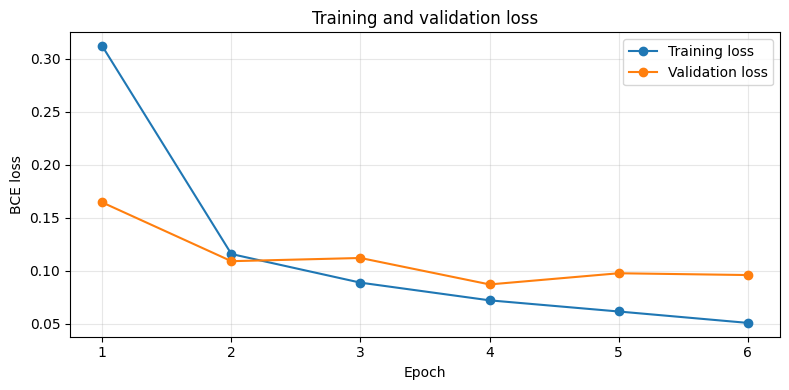

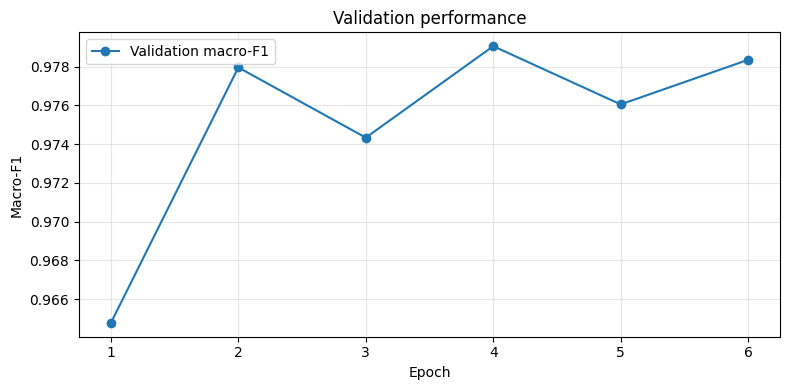

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training loss')
ax.plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation loss')
ax.set_xlabel('Epoch'); ax.set_ylabel('BCE loss'); ax.set_title('Training and validation loss')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df['epoch'], history_df['val_macro_f1'], marker='o', label='Validation macro-F1')
ax.set_xlabel('Epoch'); ax.set_ylabel('Macro-F1'); ax.set_title('Validation performance')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## 18. Reload the best saved model and evaluate on the untouched test split

Threshold: 0.5
Subset accuracy (both labels must match): 0.9667
Macro F1: 0.9839

Per-class report:
              precision    recall  f1-score   support

        Fire       0.99      1.00      1.00       392
       Smoke       0.98      0.97      0.97       424

   micro avg       0.98      0.98      0.98       816
   macro avg       0.98      0.98      0.98       816
weighted avg       0.98      0.98      0.98       816
 samples avg       0.99      0.99      0.99       816



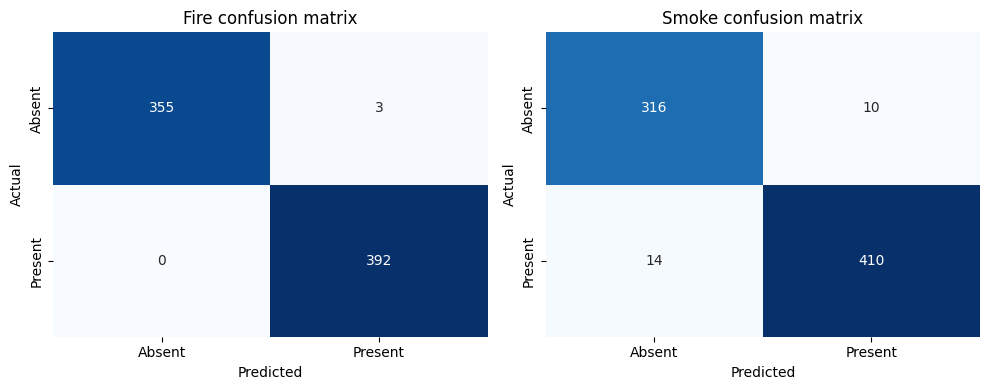

Test results and training history saved to Drive.


In [ ]:
best_model = ViTForImageClassification.from_pretrained(str(BEST_MODEL_DIR)).to(DEVICE)
best_model.eval()

@torch.no_grad()
def predict_loader(loader):
    probs_all, labels_all = [], []
    for pixel_values, labels in loader:
        pixel_values = pixel_values.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            logits = best_model(pixel_values=pixel_values).logits
        probs_all.append(torch.sigmoid(logits).cpu().numpy())
        labels_all.append(labels.numpy())
    return np.concatenate(probs_all), np.concatenate(labels_all).astype(int)

test_probs, y_test = predict_loader(test_loader)
test_pred = (test_probs >= THRESHOLD).astype(int)

print("Threshold:", THRESHOLD)
print("Subset accuracy (both labels must match):", round(accuracy_score(y_test, test_pred), 4))
print("Macro F1:", round(f1_score(y_test, test_pred, average='macro', zero_division=0), 4))
print("\nPer-class report:")
print(classification_report(
    y_test, test_pred, target_names=CLASS_NAMES, zero_division=0
))

cms = multilabel_confusion_matrix(y_test, test_pred)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in enumerate(axes):
    sns.heatmap(cms[i], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f"{CLASS_NAMES[i]} confusion matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_xticklabels(['Absent', 'Present']); ax.set_yticklabels(['Absent', 'Present'])
plt.tight_layout(); plt.show()

test_results = {
    'threshold': THRESHOLD,
    'subset_accuracy': float(accuracy_score(y_test, test_pred)),
    'macro_f1': float(f1_score(y_test, test_pred, average='macro', zero_division=0)),
    'class_names': CLASS_NAMES,
    'test_images': int(len(y_test))
}
with open(DRIVE_PROJECT / 'test_results.json', 'w') as f:
    json.dump(test_results, f, indent=2)
history_df.to_csv(DRIVE_PROJECT / 'training_history.csv', index=False)
print("Test results and training history saved to Drive.")

## 19. Inspect predictions on test images

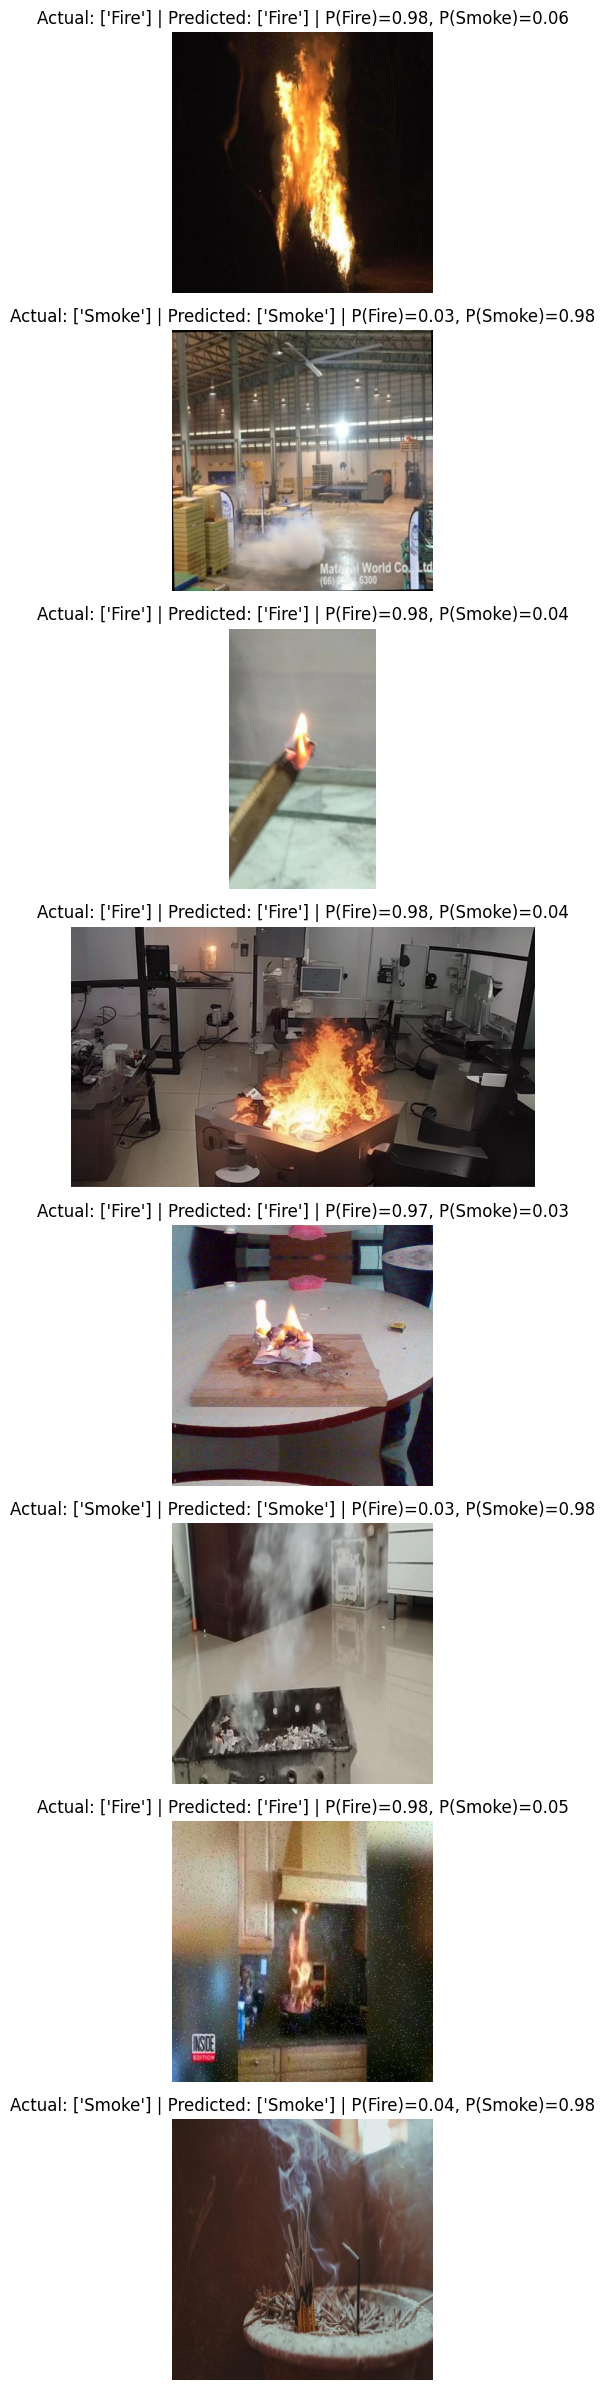

In [ ]:
test_frame = test_df.reset_index(drop=True)
n_show = min(8, len(test_frame))
indices = np.linspace(0, len(test_frame)-1, n_show, dtype=int)

fig, axes = plt.subplots(n_show, 1, figsize=(8, 3*n_show))
if n_show == 1: axes = [axes]
for ax, idx in zip(axes, indices):
    row = test_frame.iloc[idx]
    image = Image.open(row['image_path']).convert('RGB')
    probs = test_probs[idx]
    actual = [CLASS_NAMES[j] for j, v in enumerate(y_test[idx]) if v == 1]
    predicted = [CLASS_NAMES[j] for j, v in enumerate(test_pred[idx]) if v == 1]
    ax.imshow(image)
    ax.set_title(f"Actual: {actual} | Predicted: {predicted} | P(Fire)={probs[0]:.2f}, P(Smoke)={probs[1]:.2f}")
    ax.axis('off')
plt.tight_layout(); plt.show()

## 20. Save a final portable copy of the best model

In [ ]:
# The best checkpoint is already stored persistently in Drive.
# Zip the model directory for an optional copy to your computer.
portable_zip = shutil.make_archive(
    str(DRIVE_PROJECT / 'ViT_Fire_Smoke_Best_Model'),
    'zip',
    root_dir=str(BEST_MODEL_DIR)
)
print("Best model directory:", BEST_MODEL_DIR)
print("Portable model ZIP:", portable_zip)
print("Model files:")
for p in sorted(BEST_MODEL_DIR.iterdir()):
    print(" -", p.name)

Best model directory: /content/drive/MyDrive/ViT_Fire_Smoke_Project/best_model
Portable model ZIP: /content/drive/MyDrive/ViT_Fire_Smoke_Project/ViT_Fire_Smoke_Best_Model.zip
Model files:
 - class_labels.json
 - config.json
 - model.safetensors
 - preprocessor_config.json


## 21. Reload later and predict a new image — no fine-tuning

Saving SMOKE_EXAMPLE.jpg to SMOKE_EXAMPLE.jpg


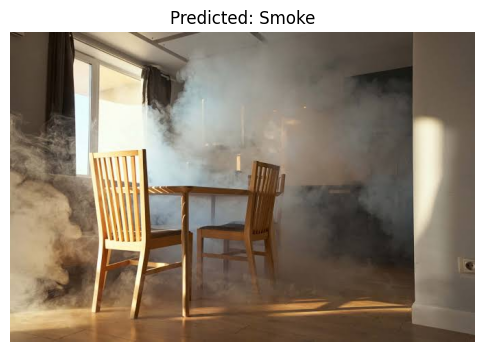

Probabilities: {'Fire': 0.0326, 'Smoke': 0.9789}
Threshold: 0.5


In [ ]:
# Run this section in a future Colab session after mounting Drive.
# Do not rerun the training cells just to predict.
from google.colab import files

inference_model = ViTForImageClassification.from_pretrained(str(BEST_MODEL_DIR)).to(DEVICE)
inference_processor = ViTImageProcessor.from_pretrained(str(BEST_MODEL_DIR))
inference_model.eval()

uploaded = files.upload()
for filename in uploaded:
    image = Image.open(filename).convert('RGB')
    inputs = inference_processor(images=image, return_tensors='pt')
    pixel_values = inputs['pixel_values'].to(DEVICE)

    with torch.no_grad():
        logits = inference_model(pixel_values=pixel_values).logits
        probs = torch.sigmoid(logits)[0].cpu().numpy()

    predictions = {
        'Fire': float(probs[0]),
        'Smoke': float(probs[1])
    }
    labels = [name for name, prob in predictions.items() if prob >= THRESHOLD]

    plt.figure(figsize=(6, 5))
    plt.imshow(image); plt.axis('off')
    plt.title(f"Predicted: {', '.join(labels) if labels else 'Neither above threshold'}")
    plt.show()

    print("Probabilities:", {k: round(v, 4) for k, v in predictions.items()})
    print("Threshold:", THRESHOLD)

## 22. Important interpretation and academic reporting notes
- The model predicts image-level Fire and Smoke presence; it does not output bounding boxes.
- Bounding boxes are used only to derive image-level labels and inspect annotation quality.
- `THRESHOLD = 0.5` is a starting decision threshold. If tuning it, use validation data only, never the test set.
- Subset accuracy requires both labels to match exactly; macro-F1 averages performance across the two labels.
- Do not claim results before running the experiment. Report actual values from the notebook.
- Exact hash matching checks identical files across splits, but does not detect all near-duplicates.
- The notebook stops when missing, empty, or malformed annotations are found. Verify the dataset convention before deciding how to handle them; do not automatically convert empty files to negative examples.
- Use modest augmentation only on training images. Validation and test images are never augmented.
- Keep the Drive folder `ViT_Fire_Smoke_Project/best_model` intact. It contains the trained weights and processor configuration needed for inference without fine-tuning.